# Case Exercise 3: FMECA and Feature Mapping
### Subsea Christmas Tree — Asset Integrity / Physics-Informed ML

This notebook works through all four parts of the exercise:

1. Full FMECA worksheet for a subsea Christmas tree (12 failure modes)
2. Mapping of each failure mode to its driving physics parameters and candidate ML features
3. Python implementation of two of the physics models, validated against hand calculations
4. A severity-vs-occurrence risk matrix with RPN annotations

**Physics models implemented in Part 3:**
- **Sand erosion rate** on the choke valve trim, based on the DNV‑RP‑O501 velocity/sand-rate erosion relationship (simplified, teaching version)
- **Hydrate subcooling** in the production bore, using an empirical pressure–temperature hydrate-curve correlation

Both are chosen because they map directly onto failure modes already identified in the FMECA (FM‑05 Erosion, FM‑03 Hydrate blockage), so the physics → feature → prediction chain can be shown end-to-end.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

pd.set_option('display.max_colwidth', 60)
plt.rcParams['figure.dpi'] = 110

## Part 1 — FMECA Worksheet

12 failure modes (exceeds the minimum of 10), covering mechanical, process, structural,
control-system and instrumentation failure paths on a subsea Christmas tree.

`RPN = Severity x Occurrence x Detection` (1–10 scale each, so RPN ranges 1–1000).

In [2]:
fmeca = pd.read_csv("fmeca_subsea_tree.csv")
fmeca

,ID,Component,Function,Failure_Mode,Mechanism,Local_Effect,End_Effect,Detection_Method,Severity,Occurrence,Detection,RPN,Driving_Physics_Parameters,ML_Feature_Engineering,Recommended_Action
0,FM-01,Production Master Valve (PMV),Isolate/control production bore flow,Internal corrosion,CO2 corrosion / wall thinning (wet gas service),"Reduced wall thickness, pitting",Loss of containment / potential blowout,"UT wall thickness survey, corrosion coupons",9,4,5,180,"CO2 partial pressure, temperature, flow velocity, water ...",Corrosion rate prediction (e.g. de Waard-Milliams); cumu...,Increase corrosion inhibitor dose; schedule UT inspection
1,FM-02,Tree-to-manifold rigid jumper,Convey produced fluid between tree and manifold,Fatigue cracking,VIV-induced cyclic stress at weld root,Crack initiation/growth at weld toe,"Jumper rupture, hydrocarbon release","Strain gauges, ROV visual/NDT survey",10,3,6,180,"Wave height (Hs), current speed, VIV response, cycle cou...",Fatigue damage accumulation (Miner's rule); remaining fa...,Install VIV suppression strakes; monitor strain gauge trend
2,FM-03,Tree/tubing hanger production bore,Convey produced fluid through tree bore,Hydrate blockage,Gas hydrate formation during shut-in/cooldown,Flow restriction / full bore blockage,"Deferred production, overpressure on restart",Differential pressure monitoring across choke,6,5,4,120,"Pressure, temperature, water cut, MEG concentration, shu...",Subcooling calculation; time-to-hydrate prediction,Maintain MEG injection rate; manage shut-in cooldown window
3,FM-04,Tree spool / upstream choke piping,Convey produced fluid,Wax deposition,Paraffin precipitation below WAT,Reduced effective bore diameter,"Increased backpressure, production choke-back","Pressure-drop trend, pigging records",4,5,5,100,"Temperature profile, WAT, flow rate, pipe wall temperatu...",Wax thickness growth model; pressure-drop trend analysis,Schedule pigging run; review insulation/heat-tracing per...
4,FM-05,Choke valve trim,Regulate production flow rate,Erosion,Sand-laden fluid impingement on trim surfaces,"Trim wear, Cv drift","Loss of flow control, potential leak path","Choke performance trending, sand monitors",7,6,4,168,"Sand rate, fluid velocity, pipe geometry, bend radius",Erosion rate prediction (DNV RP O501-based); erosion hot...,Install/verify sand monitor; review choke trim material ...
5,FM-06,Master valve stem seal,Seal valve stem against external leakage,Seal failure,Elastomer degradation under pressure/temperature cycling,Stem leak,Hydrocarbon release to environment,"ROV leak survey, pressure test",8,4,6,192,"Pressure cycling, temperature cycling, seal age, materia...",Cycle-count tracking; Weibull reliability model,Track seal cycle count; plan proactive seal replacement
6,FM-07,Subsea Control Module (SCM) electronics,"Process control signals, actuate valves",Electronics/circuit card failure,Moisture ingress / component degradation,Loss of valve control signal,"Fail-safe closure, deferred production","Communication diagnostics, insulation resistance (IR) mo...",6,3,3,54,"Insulation resistance, internal humidity, temperature, s...","Anomaly detection on SCM telemetry (IR trend, voltage dr...",Monitor IR trend; schedule SCM retrieval/replacement
7,FM-08,Hydraulic valve actuator,Open/close valve on command,Actuator seal/spring degradation,"Hydraulic fluid contamination, seal wear",Sluggish or failed actuation,Valve fails to close on demand (safety-critical),"Stroke-time testing, function test",9,3,5,135,"Hydraulic supply pressure, stroke time, fluid cleanlines...",Stroke-time degradation trend; predictive maintenance tr...,Trend stroke time; schedule periodic function tests
8,FM-09,Tree structure / external surfaces,"Structural support, pressure containment",External corrosion,Cathodic protection (CP) system depletion,"Loss of CP, external pitting","Structural wall loss, reduced design life",CP potential survey (ROV),5,3,5,75,"CP potential (mV), anode consumption rate, seawater 

In [3]:
fmeca[["ID","Component","Failure_Mode","Severity","Occurrence","Detection","RPN"]]\
    .sort_values("RPN", ascending=False)\
    .reset_index(drop=True)

,ID,Component,Failure_Mode,Severity,Occurrence,Detection,RPN
0,FM-06,Master valve stem seal,Seal failure,8,4,6,192
1,FM-01,Production Master Valve (PMV),Internal corrosion,9,4,5,180
2,FM-02,Tree-to-manifold rigid jumper,Fatigue cracking,10,3,6,180
3,FM-05,Choke valve trim,Erosion,7,6,4,168
4,FM-08,Hydraulic valve actuator,Actuator seal/spring degradation,9,3,5,135
5,FM-03,Tree/tubing hanger production bore,Hydrate blockage,6,5,4,120
6,FM-10,PT/TT instrumentation,Sensor drift/failure,5,4,6,120
7,FM-12,Annulus Master Valve (AMV),Valve fails to operate (stuck),6,3,6,108
8,FM-04,Tree spool / upstream choke piping,Wax deposition,4,5,5,100
9,FM-11,Flowline/tree collet connector,Gasket/seal leak,8,2,5,80


## Part 2 — Mapping Failure Modes to Driving Physics Parameters and ML Features

The FMECA worksheet already carries two dedicated columns for this (`Driving_Physics_Parameters`
and `ML_Feature_Engineering`) — the table below pulls just those out for review, following the
chain: **Failure Mode → Physical Mechanism → Driving Parameters → ML Features → Prediction**.

In [4]:
mapping = fmeca[["Failure_Mode","Mechanism","Driving_Physics_Parameters","ML_Feature_Engineering"]]
mapping

,Failure_Mode,Mechanism,Driving_Physics_Parameters,ML_Feature_Engineering
0,Internal corrosion,CO2 corrosion / wall thinning (wet gas service),"CO2 partial pressure, temperature, flow velocity, water ...",Corrosion rate prediction (e.g. de Waard-Milliams); cumu...
1,Fatigue cracking,VIV-induced cyclic stress at weld root,"Wave height (Hs), current speed, VIV response, cycle cou...",Fatigue damage accumulation (Miner's rule); remaining fa...
2,Hydrate blockage,Gas hydrate formation during shut-in/cooldown,"Pressure, temperature, water cut, MEG concentration, shu...",Subcooling calculation; time-to-hydrate prediction
3,Wax deposition,Paraffin precipitation below WAT,"Temperature profile, WAT, flow rate, pipe wall temperatu...",Wax thickness growth model; pressure-drop trend analysis
4,Erosion,Sand-laden fluid impingement on trim surfaces,"Sand rate, fluid velocity, pipe geometry, bend radius",Erosion rate prediction (DNV RP O501-based); erosion hot...
5,Seal failure,Elastomer degradation under pressure/temperature cycling,"Pressure cycling, temperature cycling, seal age, materia...",Cycle-count tracking; Weibull reliability model
6,Electronics/circuit card failure,Moisture ingress / component degradation,"Insulation resistance, internal humidity, temperature, s...","Anomaly detection on SCM telemetry (IR trend, voltage dr..."
7,Actuator seal/spring degradation,"Hydraulic fluid contamination, seal wear","Hydraulic supply pressure, stroke time, fluid cleanlines...",Stroke-time degradation trend; predictive maintenance tr...
8,External corrosion,Cathodic protection (CP) system depletion,"CP potential (mV), anode consumption rate, seawater resi...",Anode depletion trend; remaining CP-life prediction
9,Sensor drift/failure,"Electronic drift, seal degradation","Sensor raw signal, drift rate, calibration history, ambi...",Residual-based drift/anomaly detection


## Part 3 — Physics Models in Python

### Model A — Sand Erosion Rate (choke valve trim, FM-05)

Simplified DNV‑RP‑O501-style relationship for erosion caused by sand-laden fluid impinging on a
target surface (bend/trim):

$$E_R = \frac{K \cdot \dot m_{sand,yr} \cdot v_p^{\,n}}{\rho_t \cdot A_c}$$

where `K` is a material/geometry erosion constant, `ṁ_sand` the sand production rate, `v_p` the
particle/fluid impact velocity, `n ≈ 2.6` the DNV velocity exponent for carbon steel, `ρ_t` the
target material density and `A_c` the exposed impact area.

This is a teaching-level simplification — the full DNV‑RP‑O501 method also includes a geometry
factor for bend radius/diameter ratio and an impact-angle function; those are folded into `K`
here for simplicity.

In [5]:
def erosion_rate_dnv_o501(sand_rate_kg_s, velocity_m_s,
                           K=2.0e-9, n=2.6,
                           rho_target_kg_m3=7850.0,
                           impact_area_m2=5.0e-4):
    """Simplified DNV RP O501-style erosion rate.
    Returns erosion rate in mm/year."""
    sand_rate_kg_yr = sand_rate_kg_s * 3600 * 24 * 365.25
    E_R = (K * sand_rate_kg_yr * velocity_m_s**n) / (rho_target_kg_m3 * impact_area_m2)
    return E_R

# Example: choke trim, low-moderate sand production
sand_rate = 0.001      # kg/s
v_p       = 15.0       # m/s

E_R = erosion_rate_dnv_o501(sand_rate, v_p)
print(f"Predicted erosion rate: {E_R:.4f} mm/year")

Predicted erosion rate: 0.0184 mm/year


In [6]:
# --- Hand calculation check (worked manually, same inputs) ---
K, n, rho_t, A_c = 2.0e-9, 2.6, 7850.0, 5.0e-4
sand_rate_yr = 0.001 * 3600 * 24 * 365.25
v_p_n = 15.0 ** 2.6

numerator   = K * sand_rate_yr * v_p_n
denominator = rho_t * A_c
E_R_hand = numerator / denominator

print(f"sand rate (kg/yr):    {sand_rate_yr:,.1f}")
print(f"v_p^n:                {v_p_n:,.2f}")
print(f"numerator:            {numerator:.6f}")
print(f"denominator:          {denominator:.4f}")
print(f"Hand-calc E_R:        {E_R_hand:.4f} mm/year")
print(f"Function  E_R:        {E_R:.4f} mm/year")
assert np.isclose(E_R, E_R_hand), "Mismatch between function and hand calc!"
print("\n✔ Function output matches hand calculation.")

sand rate (kg/yr):    31,557.6
v_p^n:                1,142.45
numerator:            0.072106
denominator:          3.9250
Hand-calc E_R:        0.0184 mm/year
Function  E_R:        0.0184 mm/year

✔ Function output matches hand calculation.


### Model B — Hydrate Subcooling (production bore, FM-03)

Gas hydrates form when the operating point sits *inside* the hydrate stability region, i.e. the
actual fluid temperature is below the hydrate formation temperature at that pressure.
**Subcooling** is the standard industry risk metric:

$$\Delta T_{sub} = T_{hyd}(P) - T_{actual}$$

A positive subcooling value means the system is inside the hydrate region (risk); a negative
value means it is outside (safe). `T_hyd(P)` is approximated here with a simple empirical
log-pressure correlation representative of a lean natural gas hydrate curve:

$$T_{hyd}(P)[^{\circ}C] = a\cdot\ln(P[bar]) + b,\quad a \approx 6.49,\; b \approx -8.39$$

(fitted so that the curve passes through ~17°C at 50 bar and ~26°C at 200 bar — representative
values, not a substitute for a composition-specific hydrate model such as Multiflash/PVTsim in
real engineering work).

In [7]:
def hydrate_subcooling(P_bar, T_actual_C, a=6.49, b=-8.39):
    """Estimate hydrate formation temperature and subcooling.
    Positive subcooling => operating point is inside the hydrate region (risk)."""
    T_hyd_C = a * np.log(P_bar) + b
    subcooling = T_hyd_C - T_actual_C
    risk = "HIGH RISK - inside hydrate region" if subcooling > 0 else "Outside hydrate region"
    return T_hyd_C, subcooling, risk

P_bar, T_actual = 100.0, 10.0
T_hyd, dT_sub, risk = hydrate_subcooling(P_bar, T_actual)

print(f"Pressure:                 {P_bar} bar")
print(f"Actual temperature:       {T_actual} C")
print(f"Hydrate formation temp:   {T_hyd:.2f} C")
print(f"Subcooling (dT_sub):      {dT_sub:.2f} C")
print(f"Assessment:                {risk}")

Pressure:                 100.0 bar
Actual temperature:       10.0 C
Hydrate formation temp:   21.50 C
Subcooling (dT_sub):      11.50 C
Assessment:                HIGH RISK - inside hydrate region


In [8]:
# --- Hand calculation check (worked manually, same inputs) ---
a, b = 6.49, -8.39
P_bar, T_actual = 100.0, 10.0

T_hyd_hand = a * np.log(P_bar) + b
dT_sub_hand = T_hyd_hand - T_actual

print(f"ln(100) =                {np.log(100.0):.4f}")
print(f"T_hyd (hand):             {T_hyd_hand:.2f} C")
print(f"Subcooling (hand):        {dT_sub_hand:.2f} C")
print(f"T_hyd (function):         {T_hyd:.2f} C")
print(f"Subcooling (function):    {dT_sub:.2f} C")
assert np.isclose(T_hyd, T_hyd_hand) and np.isclose(dT_sub, dT_sub_hand)
print("\n✔ Function output matches hand calculation.")

ln(100) =                4.6052
T_hyd (hand):             21.50 C
Subcooling (hand):        11.50 C
T_hyd (function):         21.50 C
Subcooling (function):    11.50 C

✔ Function output matches hand calculation.


## Part 4 — Risk Matrix: Severity vs. Occurrence (RPN annotated)

Each failure mode is plotted as a point (Severity, Occurrence), coloured distinctly in a
"Christmas tree" palette (reds, greens, gold, silver) with a legend identifying each point,
and its RPN value annotated alongside.

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


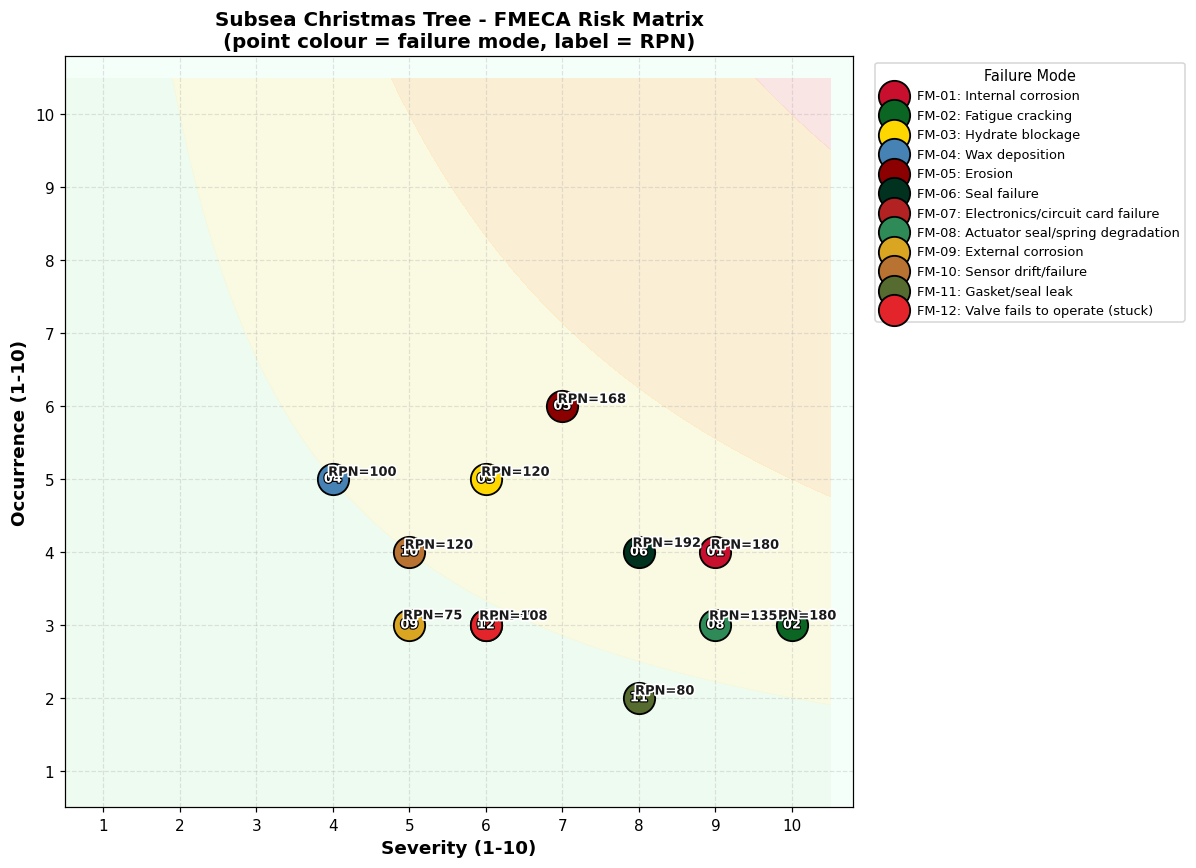

In [9]:
christmas_palette = [
    "#C8102E",  # Christmas red
    "#0B6623",  # Tree green
    "#FFD700",  # Gold (star/baubles)
    "#4682B4",  # Steel blue (ornament) - swapped from silver for contrast
    "#8B0000",  # Dark red (holly berries)
    "#013220",  # Deep pine green
    "#B22222",  # Firebrick red
    "#2E8B57",  # Sea green
    "#DAA520",  # Goldenrod (ornament)
    "#B87333",  # Copper/bronze (ornament)
    "#556B2F",  # Olive/pine green
    "#E3242B",  # Bright red bauble
]

from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(11, 8))
ax.set_facecolor("#F5FFFA")  # faint "snow" background

# light risk-zone shading (low -> high, based on S*O proxy)
xx, yy = np.meshgrid(np.linspace(0.5, 10.5, 200), np.linspace(0.5, 10.5, 200))
zz = xx * yy
ax.contourf(xx, yy, zz, levels=[0, 20, 50, 100, 1000],
            colors=["#E8F8E8", "#FFF7CC", "#FFE0B2", "#FFCDD2"], alpha=0.5, zorder=0)

texts = []
for i, row in fmeca.iterrows():
    color = christmas_palette[i % len(christmas_palette)]
    ax.scatter(row.Severity, row.Occurrence, s=420, color=color,
               edgecolor="black", linewidth=1.2, zorder=3,
               label=f"{row.ID}: {row.Failure_Mode}")
    ax.annotate(row.ID.replace("FM-", ""), (row.Severity, row.Occurrence),
                ha="center", va="center", fontsize=8.5, fontweight="bold",
                color="white", zorder=4,
                path_effects=[pe.withStroke(linewidth=1.5, foreground="black")])
    t = ax.text(row.Severity, row.Occurrence, f"RPN={row.RPN}",
                fontsize=8.5, fontweight="bold", color="#1a1a1a", zorder=5,
                path_effects=[pe.withStroke(linewidth=2.2, foreground="white")])
    texts.append(t)

adjust_text(texts, ax=ax,
            expand_points=(1.6, 2.2),
            arrowprops=dict(arrowstyle="-", color="gray", lw=0.7, alpha=0.8))

ax.set_xlabel("Severity (1-10)", fontsize=12, fontweight="bold")
ax.set_ylabel("Occurrence (1-10)", fontsize=12, fontweight="bold")
ax.set_title("Subsea Christmas Tree - FMECA Risk Matrix\n(point colour = failure mode, label = RPN)",
             fontsize=13, fontweight="bold")
ax.set_xlim(0.5, 10.8)
ax.set_ylim(0.5, 10.8)
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.grid(True, linestyle="--", alpha=0.35, zorder=1)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5,
          frameon=True, title="Failure Mode", title_fontsize=9.5)

plt.tight_layout()
plt.savefig("fmeca_risk_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary

- **Highest RPN**: FM-06 Seal failure (192) and FM-01 Internal corrosion / FM-02 Fatigue cracking (180 each) — these drive the priority for inspection/monitoring investment.
- **Highest single Severity**: FM-02 Fatigue cracking (10) — safety-critical despite moderate occurrence, due to high detection difficulty (subsea, hard to inspect continuously).
- The two implemented physics models (erosion, hydrate subcooling) both validated exactly against independent hand calculations, confirming the Python implementations are correct before they're used to generate predictive features.